In [1]:
import os
import sys

from osgeo import gdal

import shapefile
import overpy
from shapely.geometry.polygon import LinearRing, Polygon, LineString, Point
from shapely.geometry import MultiPolygon
import pandas as pd
from area import area
import dill
import numpy as np
import math
from math import log, exp, tan, atan, ceil


from io import BytesIO
import urllib.request as req

from geopy.distance import great_circle
import json
import requests
import urllib.request

import traceback
import random


from matplotlib import *
from matplotlib import pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib import gridspec
from matplotlib_scalebar.scalebar import ScaleBar
from PIL import Image

import io
from shapely import geometry
from shapely.geometry import Polygon, Point, shape, LineString, MultiPolygon
from shapely import ops
from shapely.geometry.polygon import LinearRing, Polygon
from shapely.wkt import loads
from area import area

import datetime

from pyproj import Transformer

import cv2

In [2]:
def point_in_poly(poly, point_lat, point_lon):

    point_chk = Point(point_lon, point_lat)
    if(point_chk.within(poly)):
        return 1
    else:
        return 0
    
def polyToPointList(poly):
    pnt_list = []
    x, y = poly.exterior.xy
    for i, x_ in enumerate(x):
        pnt_list.append([x[i], y[i]])
    return pnt_list


def lineToPointList(line_):
    pnt_list = []
    if(line_.geom_type == 'MultiLineString'):
        for it in line_:
            x, y = it.xy
            for i, x_ in enumerate(x):
                pnt_list.append([x[i], y[i]])
    else:
        x, y = line_.xy
        for i, x_ in enumerate(x):
            pnt_list.append([x[i], y[i]])
    return pnt_list


def getRouteLen(ptlist):
    x, y = [i[0] for i in ptlist], [i[1] for i in ptlist]
    len_ = 0
    j = 0
    for i, x_ in enumerate(x):
        if(i <= len(x) - 2):
            len_ = len_ + \
                great_circle((y[i], x[i]), (y[i + 1], x[i + 1])).meters

    return round(len_, 3)

In [3]:
TRAN_3857_TO_4326 = Transformer.from_crs( "EPSG:3857","EPSG:4326")

def mytransform(lon, lat):
    
    return TRAN_3857_TO_4326.transform(lon, lat)


In [4]:
path='C:/Users/esurmon/Downloads/DTAC_QGIS_PROJ/Smaller/grid.shp'
sf = shapefile.Reader(path)

grid_id=[]
image_name=[]

tiff_path='geotiff/tiffs'
files=os.listdir(tiff_path)

mapped_grid_ids=[]
for f in files:
    if f.endswith(".tif"):
        ds = gdal.Open(tiff_path+'/'+f)
        width = ds.RasterXSize
        height = ds.RasterYSize
        gt = ds.GetGeoTransform()

        minx = gt[0]
        miny = gt[3] + width*gt[4] + height*gt[5] 
        maxx = gt[0] + width*gt[1] + height*gt[2]
        maxy = gt[3]

        #CENTROIDS OF IMAGES
        c_x=(minx+maxx)/2
        c_y=(miny+maxy)/2
        
        cy,cx=mytransform(c_x,c_y)
        
        for shaperec in sf.iterShapeRecords():
    
            if(pd.isna(shaperec.record[0])==False and shaperec.record[0] not in grid_id):

                #print(shaperec.record[0])

                grid_polygon=Polygon((shaperec.shape.points))

                if(point_in_poly(grid_polygon,cy,cx)==1):
                    """
                    print(grid_polygon.centroid.x,grid_polygon.centroid.y)
                    print(b,a)
                    print("YES",shaperec.record[0])
                    
                    """
                    #print(shaperec.record[0],f)
                    grid_id.append(shaperec.record[0])
                    image_name.append(os.path.abspath(os.path.join('..')).replace("\\","/")+'/'+tiff_path+'/'+f)

                    break
                    
filename_map=pd.DataFrame()
filename_map['GRID_ID']=grid_id
filename_map['IMAGE_NAME']=image_name


In [5]:
filename_map.to_csv('geotiff/filename_map.csv',index=False)

### TESTING

In [88]:
path='C:/Users/esurmon/Downloads/DTAC_QGIS_PROJ/Smaller/grid.shp'
sf = shapefile.Reader(path)

grid_id=[]
image_name=[]

tiff_path='geotiff/New folder'
files=os.listdir(tiff_path)

mapped_grid_ids=[]
for f in files:

    if f.endswith(".tif")  and f=='New folder.75.tif':
        ds = gdal.Open(tiff_path+'/'+f)
        width = ds.RasterXSize
        height = ds.RasterYSize
        gt = ds.GetGeoTransform()

        minx = gt[0]
        miny = gt[3] + width*gt[4] + height*gt[5] 
        maxx = gt[0] + width*gt[1] + height*gt[2]
        maxy = gt[3]

        #CENTROIDS OF IMAGES
        c_x=(minx+maxx)/2
        c_y=(miny+maxy)/2
        
        cy,cx=mytransform(c_x,c_y)
        
        for shaperec in sf.iterShapeRecords():
    
            if(pd.isna(shaperec.record[0])==False):

                #print(shaperec.record[0])

                grid_polygon=Polygon((shaperec.shape.points))

                if(point_in_poly(grid_polygon,cy,cx)==1):
                    """
                    print(grid_polygon.centroid.x,grid_polygon.centroid.y)
                    print(b,a)
                    print("YES",shaperec.record[0])
                    
                    """
                    print(shaperec.record[0],f)
                    grid_id.append(shaperec.record[0])
                    image_name.append(os.path.abspath(os.path.join('..')).replace("\\","/")+'/'+tiff_path+'/'+f)

                    break
                    

150 New folder.75.tif


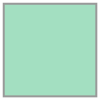

In [89]:
from shapely.ops import unary_union
unary_union([grid_polygon,Point(cx,cy).buffer(0.0001)])

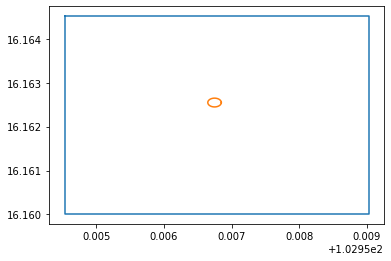

In [90]:
x,y=grid_polygon.exterior.xy
a,b=Point(cx,cy).buffer(0.0001).exterior.xy
plt.plot(x,y)
plt.plot(a,b)

In [68]:
len(grid_id)

5328

In [ ]:
for shaperec in sf.iterShapeRecords():

    if(pd.isna(shaperec.record[0])==False):

        print(shaperec.record[0])